In [163]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

In [164]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/automobile_price_prediction_dataset.csv")

In [165]:
df.head()

,Brand,Year,Fuel_Type,Transmission,Owner_Type,Body_Type,Kilometers_Driven,Mileage,Engine_CC,Max_Power_BHP,Seats,Selling_Price_Lakh
0,Volkswagen,2024,Petrol,Manual,First,Hatchback,52407,16.7,1266.0,81.1,5.0,4.42
1,Tata,2017,Diesel,Manual,First,Sedan,112716,15.8,1336.0,136.5,5.0,1.89
2,BMW,2019,Hybrid,Automatic,First,Hatchback,90826,19.9,1631.0,155.9,5.0,9.00
3,Mahindra,2014,Petrol,Manual,Second,Hatchback,97577,17.9,600.0,55.2,5.0,0.70
4,Maruti,2024,CNG,Manual,Second,Sedan,25605,25.1,1514.0,149.6,5.0,3.83


In [166]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Brand               12000 non-null  object 
 1   Year                12000 non-null  int64  
 2   Fuel_Type           12000 non-null  object 
 3   Transmission        12000 non-null  object 
 4   Owner_Type          12000 non-null  object 
 5   Body_Type           12000 non-null  object 
 6   Kilometers_Driven   12000 non-null  int64  
 7   Mileage             11580 non-null  float64
 8   Engine_CC           11785 non-null  float64
 9   Max_Power_BHP       11700 non-null  float64
 10  Seats               11856 non-null  float64
 11  Selling_Price_Lakh  12000 non-null  float64
dtypes: float64(5), int64(2), object(5)
memory usage: 1.1+ MB


In [167]:
df.columns

Index(['Brand', 'Year', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Body_Type',
       'Kilometers_Driven', 'Mileage', 'Engine_CC', 'Max_Power_BHP', 'Seats',
       'Selling_Price_Lakh'],
      dtype='object')

In [192]:
df["Brand"].value_counts()

Brand
Maruti           2322
Hyundai          1823
Tata             1429
Toyota            987
Mahindra          964
Honda             960
Kia               846
Renault           583
Ford              484
Volkswagen        478
Skoda             355
BMW               318
Mercedes-Benz     237
Audi              214
Name: count, dtype: int64

In [193]:
df["Fuel_Type"].value_counts()

Fuel_Type
Petrol      5690
Diesel      4152
CNG         1105
Electric     691
Hybrid       362
Name: count, dtype: int64

In [194]:
df["Transmission"].value_counts()

Transmission
Manual       8588
Automatic    3412
Name: count, dtype: int64

In [195]:
df["Owner_Type"].value_counts()

Owner_Type
First             7377
Second            2971
Third             1181
Fourth or more     471
Name: count, dtype: int64

In [196]:
df["Body_Type"].value_counts()

Body_Type
Hatchback    4029
SUV          3850
Sedan        2909
MUV          1212
Name: count, dtype: int64

In [191]:
df.head()

,Brand,Year,Fuel_Type,Transmission,Owner_Type,Body_Type,Kilometers_Driven,Mileage,Engine_CC,Max_Power_BHP,Seats,Selling_Price_Lakh
0,Volkswagen,2024,Petrol,Manual,First,Hatchback,52407,16.7,1266.0,81.1,5.0,4.42
1,Tata,2017,Diesel,Manual,First,Sedan,112716,15.8,1336.0,136.5,5.0,1.89
2,BMW,2019,Hybrid,Automatic,First,Hatchback,90826,19.9,1631.0,155.9,5.0,9.00
3,Mahindra,2014,Petrol,Manual,Second,Hatchback,97577,17.9,600.0,55.2,5.0,0.70
4,Maruti,2024,CNG,Manual,Second,Sedan,25605,25.1,1514.0,149.6,5.0,3.83


In [168]:
df.describe()

,Year,Kilometers_Driven,Mileage,Engine_CC,Max_Power_BHP,Seats,Selling_Price_Lakh
count,12000.000000,12000.000000,11580.000000,11785.000000,11700.000000,11856.000000,12000.000000
mean,2016.540333,117420.941667,37.642962,1551.155028,123.953231,5.353661,3.414141
std,5.206179,58705.472061,80.151554,514.628456,47.189222,0.858633,3.417388
min,2008.000000,500.000000,8.000000,600.000000,35.000000,4.000000,0.350000
25%,2012.000000,70163.750000,16.000000,1162.000000,88.600000,5.000000,1.250000
50%,2017.000000,117268.000000,18.400000,1536.000000,119.350000,5.000000,2.330000
75%,2021.000000,164836.500000,21.100000,1932.000000,154.200000,5.000000,4.350000
max,2025.000000,266008.000000,550.000000,3291.000000,317.000000,8.000000,43.420000


In [169]:
df.isnull().sum()

Brand                   0
Year                    0
Fuel_Type               0
Transmission            0
Owner_Type              0
Body_Type               0
Kilometers_Driven       0
Mileage               420
Engine_CC             215
Max_Power_BHP         300
Seats                 144
Selling_Price_Lakh      0
dtype: int64

In [170]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Brand               12000 non-null  object 
 1   Year                12000 non-null  int64  
 2   Fuel_Type           12000 non-null  object 
 3   Transmission        12000 non-null  object 
 4   Owner_Type          12000 non-null  object 
 5   Body_Type           12000 non-null  object 
 6   Kilometers_Driven   12000 non-null  int64  
 7   Mileage             11580 non-null  float64
 8   Engine_CC           11785 non-null  float64
 9   Max_Power_BHP       11700 non-null  float64
 10  Seats               11856 non-null  float64
 11  Selling_Price_Lakh  12000 non-null  float64
dtypes: float64(5), int64(2), object(5)
memory usage: 1.1+ MB


In [171]:
df["Mileage"]=df["Mileage"].fillna(df["Mileage"].mean())
df["Engine_CC"]=df["Engine_CC"].fillna(df["Engine_CC"].mean())
df["Max_Power_BHP"]=df["Max_Power_BHP"].fillna(df["Max_Power_BHP"].mean())
df["Seats"]=df["Seats"].fillna(df["Seats"].mode()[0])

In [172]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Brand               12000 non-null  object 
 1   Year                12000 non-null  int64  
 2   Fuel_Type           12000 non-null  object 
 3   Transmission        12000 non-null  object 
 4   Owner_Type          12000 non-null  object 
 5   Body_Type           12000 non-null  object 
 6   Kilometers_Driven   12000 non-null  int64  
 7   Mileage             12000 non-null  float64
 8   Engine_CC           12000 non-null  float64
 9   Max_Power_BHP       12000 non-null  float64
 10  Seats               12000 non-null  float64
 11  Selling_Price_Lakh  12000 non-null  float64
dtypes: float64(5), int64(2), object(5)
memory usage: 1.1+ MB


In [173]:
df.isnull().sum()

Brand                 0
Year                  0
Fuel_Type             0
Transmission          0
Owner_Type            0
Body_Type             0
Kilometers_Driven     0
Mileage               0
Engine_CC             0
Max_Power_BHP         0
Seats                 0
Selling_Price_Lakh    0
dtype: int64

In [174]:
df.duplicated().sum()

np.int64(0)

# Separate X and y

In [175]:
X=df.drop(columns="Selling_Price_Lakh",axis=1)
y=df["Selling_Price_Lakh"]

# Numerical and Categorical Features

In [176]:
numerical_cal=X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(include='object').columns.tolist()

In [177]:
numerical_transformer=Pipeline(steps=[
    ("impute",SimpleImputer(strategy="median")),
    ("scler",StandardScaler())
])

categorical_transformer=Pipeline(steps=[
    ("impute",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

In [178]:
preprocessing=ColumnTransformer(transformers=[
    ("num",numerical_transformer,numerical_cal),
    ("cat",categorical_transformer,categorical_cols)
])

In [179]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_test.shape)
print(y_train.shape)

(9600, 11)
(2400, 11)
(2400,)
(9600,)


# Apply Linear Regression

In [180]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('model', LinearRegression())
])

# Define Hyperparameters

In [181]:
params = {
    'model__fit_intercept': [True, False],
    'model__copy_X': [True, False],
    'model__positive': [True, False]
}

# Apply GridSearchCV

In [182]:
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=params,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1)
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__copy_X': [True, False], 'model__fit_intercept': [True, False], 'model__positive': [True, False]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection

# Prediction

In [183]:
y_pred=grid_search.predict(X_test)

# Best Parameters

In [184]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Best Parameters: {'model__copy_X': True, 'model__fit_intercept': False, 'model__positive': False}
Best CV Score: 0.7196508847948624


# Evaluation

In [185]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [186]:
mae=mean_absolute_error(y_test,y_pred)
print("MAE",mae)
mse=mean_squared_error(y_test,y_pred)
print("MSE:",mse)
R2=r2_score(y_test,y_pred)
print("R2",R2)

MAE 1.1267706927578065
MSE: 2.959509687203486
R2 0.7326271154230686


# Actual vs Predicted Visualization

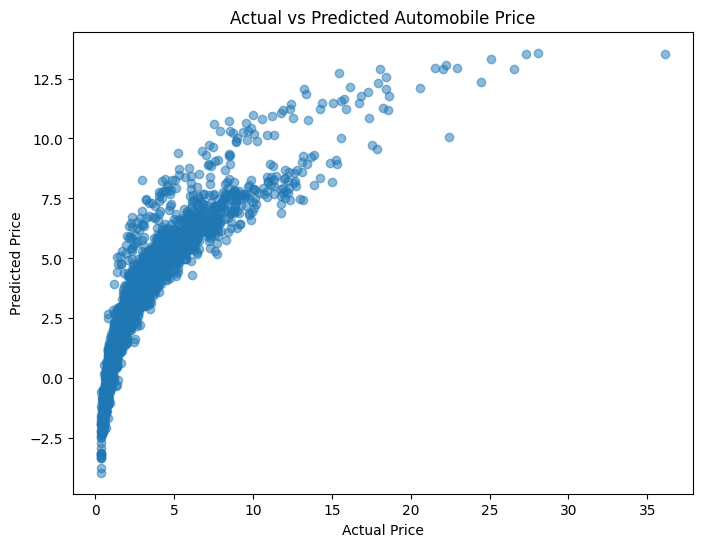

In [187]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Automobile Price")
plt.show()

# Residual Analysis

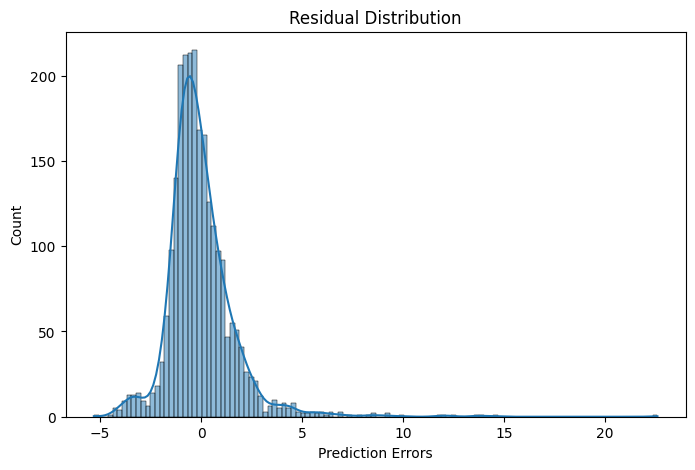

In [188]:
residuals = y_test - y_pred
plt.figure(figsize=(8,5))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.xlabel("Prediction Errors")
plt.show()

# Save Tuned Model

In [198]:
import joblib
joblib.dump(model, 'automobile_linear_regression.pkl')
print("Model Saved Successfully!")

Model Saved Successfully!


In [199]:
import joblib

joblib.dump(
    grid_search.best_estimator_,
    "automobile_linear_regression_tuned.pkl"
)

print("Model Saved Successfully!")

Model Saved Successfully!


In [200]:
import os
print(os.getcwd())

/Users/nidagallusandeep


In [201]:
import joblib

joblib.dump(
    grid_search.best_estimator_,
    "/Users/nidagallusandeep/Desktop/CAR/automobile_linear_regression_tuned.pkl"
)

print("Model Saved Successfully in CAR Folder!")

Model Saved Successfully in CAR Folder!


In [202]:
import os
print(os.listdir("/Users/nidagallusandeep/Desktop/CAR"))

['requirements.txt', '.agents', 'automobile_linear_regression_tuned.pkl', 'app.py', 'car_background_streamlit.jpg']
